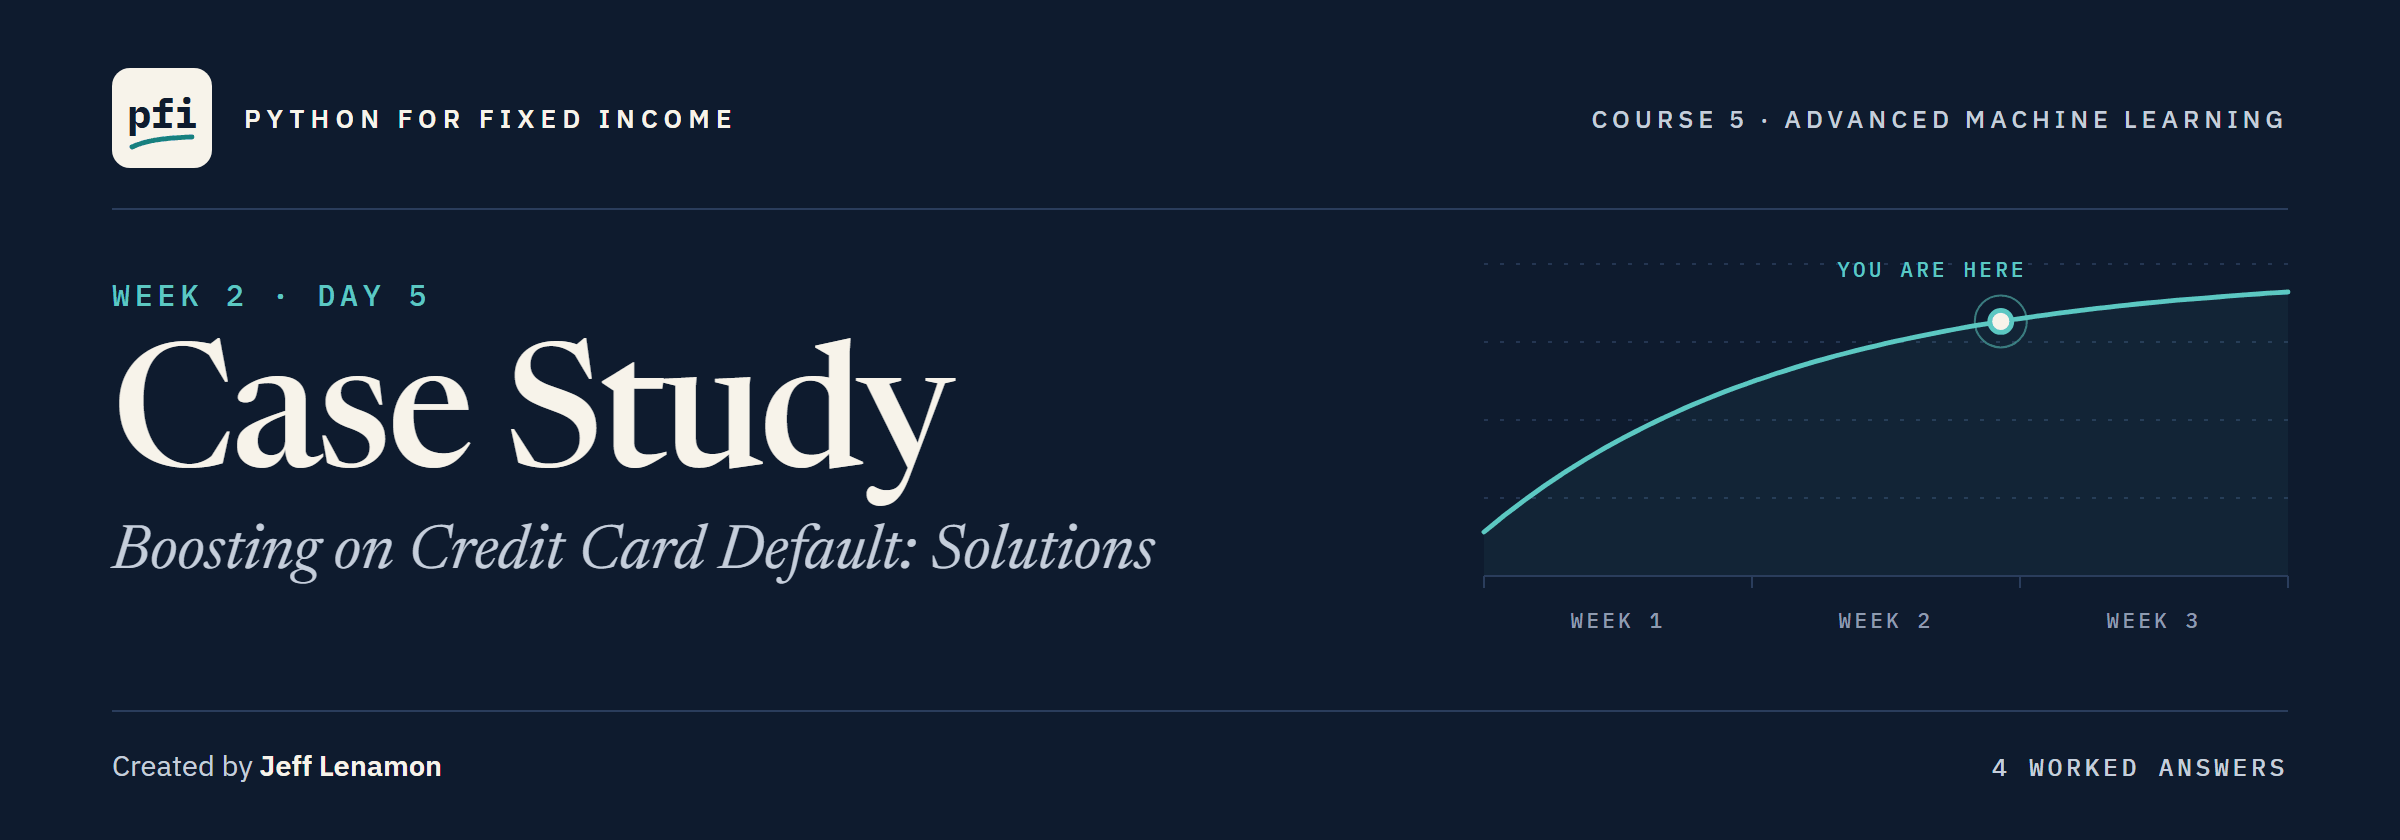

# Case Study: Boosting on Credit Card Default: Solutions

Week 2, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day5/10_case_study_boosting_on_credit_card_default_solutions.ipynb)

# Problem Statement

## Business Context

Two weeks of ensembles have been fitted to the card accounts Course 4 modelled: forests, AdaBoost, XGBoost, LightGBM and a stack.
A reviewer asks the desk's questions: which model ranks the defaults highest on accounts it never saw, by how much, is the gap more than noise, and where does the chosen one fail?
The accounts are real, from Taiwan, April to September 2005, so they describe consumer credit there and then, not US credit today.
`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are never features: a model using them would sort people by them.
A flag means "flagged at threshold t", never a credit decision about anyone.

## Objectives

Fit the course's models on the training rows, and put a bootstrap interval on a validation score and on the gap between two models.
Tune one booster with a grid inside the training rows, choose the model and its threshold from out-of-fold outputs, report every model on the validation rows, and say what the chosen model leans on and where it fails.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never features

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and two dropdowns
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, fold the training rows, and choose on the folds
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV

# the course's models: Course 4's two, Day 3's forest, Day 6's AdaBoost, Days 8 and 9's boosters
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# to score outputs and flags, and to compare outputs with default rates
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, recall_score, precision_score
from sklearn.calibration import calibration_curve

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts, as in Course 4's Day 7
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

# Loading the Data

## Reading the Card File and Choosing the Features

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
PERSON_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FEATURES = [column for column in card.columns if column not in ["ID", TARGET] + PERSON_COLUMNS]
X, y = card[FEATURES], card[TARGET]
print(len(FEATURES), "features")

19 features


## Splitting the Accounts First

In [4]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


**The same 18,000, 6,000 and 6,000 accounts as Course 4 and every notebook since; the exploration looks at the 18,000 only.**

# Data Overview

## Shape, Gaps and the Default Share

In [5]:
# rows and columns, missing values, and the defaults in the whole file
print(card.shape, " Missing values:", card.isnull().sum().sum())
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)  Missing values: 0
Defaults: 6636  Share: 22.12 percent


Nothing is missing, and 22.12 percent of the accounts defaulted.

Course 4's Day 10 explored this file in full; this notebook keeps one picture of it.

**The file is the one Course 4 used, so the overview is short and the models start sooner.**

# Exploratory Data Analysis

## Default Rate by September Status

Q. How does the default rate move with September's repayment status, on the training rows?

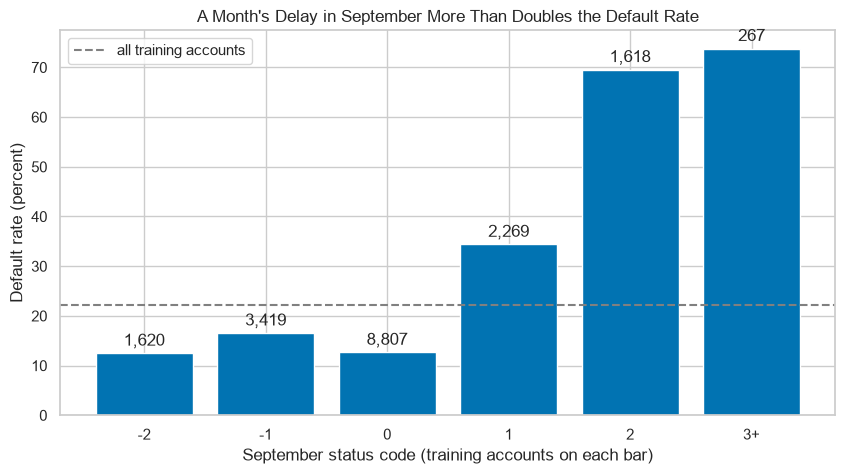

In [6]:
# September status on the training rows, codes 3 and above together, then each code's accounts and default rate
status_train = X_train["PAY_0"].clip(upper=3)
by_status = y_train.groupby(status_train).agg(["size", "mean"])

# the rate for each code, its accounts written on each bar, the training rate dashed
bars = plt.bar(["-2", "-1", "0", "1", "2", "3+"], by_status["mean"] * 100)
plt.bar_label(bars, labels=[f"{n:,}" for n in by_status["size"]], padding=3)
plt.axhline(y_train.mean() * 100, color="gray", linestyle="--", label="all training accounts")
plt.xlabel("September status code (training accounts on each bar)")
plt.ylabel("Default rate (percent)")
plt.title("A Month's Delay in September More Than Doubles the Default Rate")
plt.legend(loc="upper left")
plt.show()

In [7]:
# the default rate at each code, in percent
(by_status["mean"] * 100).round(2).to_dict()

{-2: 12.47, -1: 16.53, 0: 12.64, 1: 34.38, 2: 69.53, 3: 73.78}

The three codes 0 and below hold most of the accounts and default at 12 to 17 percent.

One month late in September more than doubles the rate; two months late, seven accounts in ten defaulted.

**Trees split on the status codes as they are, so the boosters need no transform; the logistic regression keeps Course 4's scaler.**

# Data Preparation for Modeling

## Five Folds of the Training Rows

In [8]:
# five stratified folds of the training rows: the same folds for every out-of-fold output and every search today
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Accounts in each held-out fold:", [len(held_out) for fit_rows, held_out in folds.split(X_train, y_train)])

Accounts in each held-out fold: [3600, 3600, 3600, 3600, 3600]


Five folds of 3,600 accounts, as on Day 9.

Every model is fitted and every setting and threshold chosen inside the 18,000 training rows.

The validation rows only report, and the 6,000 test rows are never scored in Course 5.

**Training rows fit and choose, validation rows report, test rows stay closed.**

# Model Building

## Model Evaluation Criterion

ROC AUC on the validation rows compares the models, with average precision beside it (Course 4's Day 8).

The desk's illustration asks for a recall of 0.70: catch 70 percent of the defaults.

Each model's threshold for it is read from the training rows, never from the validation rows.

## Six Models From Two Courses

Each model keeps the settings its own day chose.
Day 8's braked XGBoost and Day 9's LightGBM keep the tree counts their stopping rows kept, now fitted on all 18,000 training rows, as Day 9 did.

In [9]:
# Course 4's two models, Day 3's chosen forest and Day 6's 200 stumps
models = {"logistic": Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]),
          "pruned tree": DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED),
          "forest": RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, random_state=SEED, n_jobs=1),
          "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=200,
                                         random_state=SEED)}

# Day 8's braked XGBoost with its 394 trees, and Day 9's LightGBM with its 53
models["XGBoost"] = XGBClassifier(n_estimators=394, learning_rate=0.05, reg_lambda=1000, n_jobs=1, random_state=SEED)
models["LightGBM"] = LGBMClassifier(n_estimators=53, learning_rate=0.05, random_state=SEED, n_jobs=1, verbose=-1)

# all six fitted on the 18,000 training rows
for model in models.values():
    model.fit(X_train, y_train)

## Day 9's Stack, Built by Hand

Day 9's stack has four members, the logistic regression, the forest and the two boosters, and a logistic layer fitted on their **out-of-fold** outputs (Course 4's capstone): each training account's output from the fit, among five, that never saw it.
Day 9 showed `StackingClassifier` gives the same outputs; built by hand, the members' out-of-fold columns stay on the page for the thresholds later.

In [10]:
# each member's out-of-fold output for every training account: five fits per member on today's folds
MEMBERS = ["logistic", "forest", "XGBoost", "LightGBM"]
oof = pd.DataFrame({name: cross_val_predict(models[name], X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
                    for name in MEMBERS})

# the layer: a logistic regression on the four columns
layer = LogisticRegression().fit(oof, y_train)
print("Coefficients:", dict(zip(MEMBERS, layer.coef_[0].round(4).tolist())), " Intercept:", round(layer.intercept_[0], 4))

Coefficients: {'logistic': -0.6874, 'forest': 1.9285, 'XGBoost': 2.2783, 'LightGBM': 1.7874}  Intercept: -2.6485


In [11]:
# the stack's output for any rows: each member's output, then the layer's
def stack_output(rows):
    columns = pd.DataFrame({name: models[name].predict_proba(rows)[:, 1] for name in MEMBERS})
    return layer.predict_proba(columns)[:, 1]

The layer leans on XGBoost most, then the forest and LightGBM, and gives Course 4's logistic a negative weight, as on Day 9.

## Training Against Validation

In [12]:
# every model's outputs on the training and the validation rows, one column per model; the stack's from its layer
fitted = pd.DataFrame({name: model.predict_proba(X_train)[:, 1] for name, model in models.items()})
outputs = pd.DataFrame({name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()})
fitted["stack"], outputs["stack"] = stack_output(X_train), stack_output(X_valid)

# ROC AUC on both, and validation average precision, highest validation first
scores = pd.DataFrame({"training": [roc_auc_score(y_train, fitted[name]) for name in fitted],
                       "validation": [roc_auc_score(y_valid, outputs[name]) for name in outputs],
                       "average precision": [average_precision_score(y_valid, outputs[name]) for name in outputs]},
                      index=outputs.columns).sort_values("validation", ascending=False)
scores

,training,validation,average precision
stack,0.8243,0.7846,0.5575
forest,0.8204,0.7844,0.5562
XGBoost,0.8100,0.7827,0.5553
LightGBM,0.8355,0.7799,0.5526
AdaBoost,0.7867,0.7708,0.5321
pruned tree,0.7691,0.7627,0.4954
logistic,0.7296,0.7190,0.4946


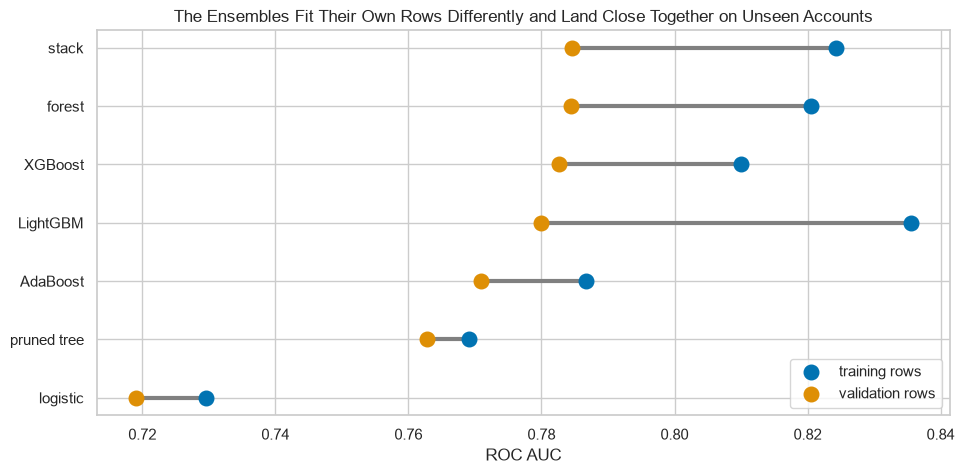

In [13]:
# Day 1's dumbbell: training against validation ROC AUC, one row per model, highest validation at the top
fig, ax = plt.subplots(figsize=(11, 5))
ax.hlines(scores.index, scores["validation"], scores["training"], color="gray", linewidth=3)
ax.scatter(scores["training"], scores.index, s=110, label="training rows", zorder=3)
ax.scatter(scores["validation"], scores.index, s=110, label="validation rows", zorder=3)
ax.invert_yaxis()
ax.set_xlabel("ROC AUC")
ax.set_title("The Ensembles Fit Their Own Rows Differently and Land Close Together on Unseen Accounts")
ax.legend(loc="lower right")
plt.show()

The five ensembles land between 0.7708 and 0.7846 on validation; Course 4's two models sit below.

The stack and the forest lead, with XGBoost close behind and LightGBM behind XGBoost.

LightGBM fits its own rows hardest and scores below XGBoost on unseen accounts.

**The ensembles land within a hundredth and a half of each other; next we ask whether XGBoost's lead over LightGBM belongs to the models or to the accounts scored.**

# Is the Gap Noise?

![One resample of the 6,000 validation accounts. The first 12 positions are drawn 1, 0, 0, 2, 0, 1, 1, 2, 0, 4, 0 and 0 times: an account drawn twice counts twice, one drawn 0 times is left out of this score. XGBoost's ROC AUC on the drawn accounts minus LightGBM's ROC AUC on the same accounts gives their difference, and the draw is repeated 1,000 times.](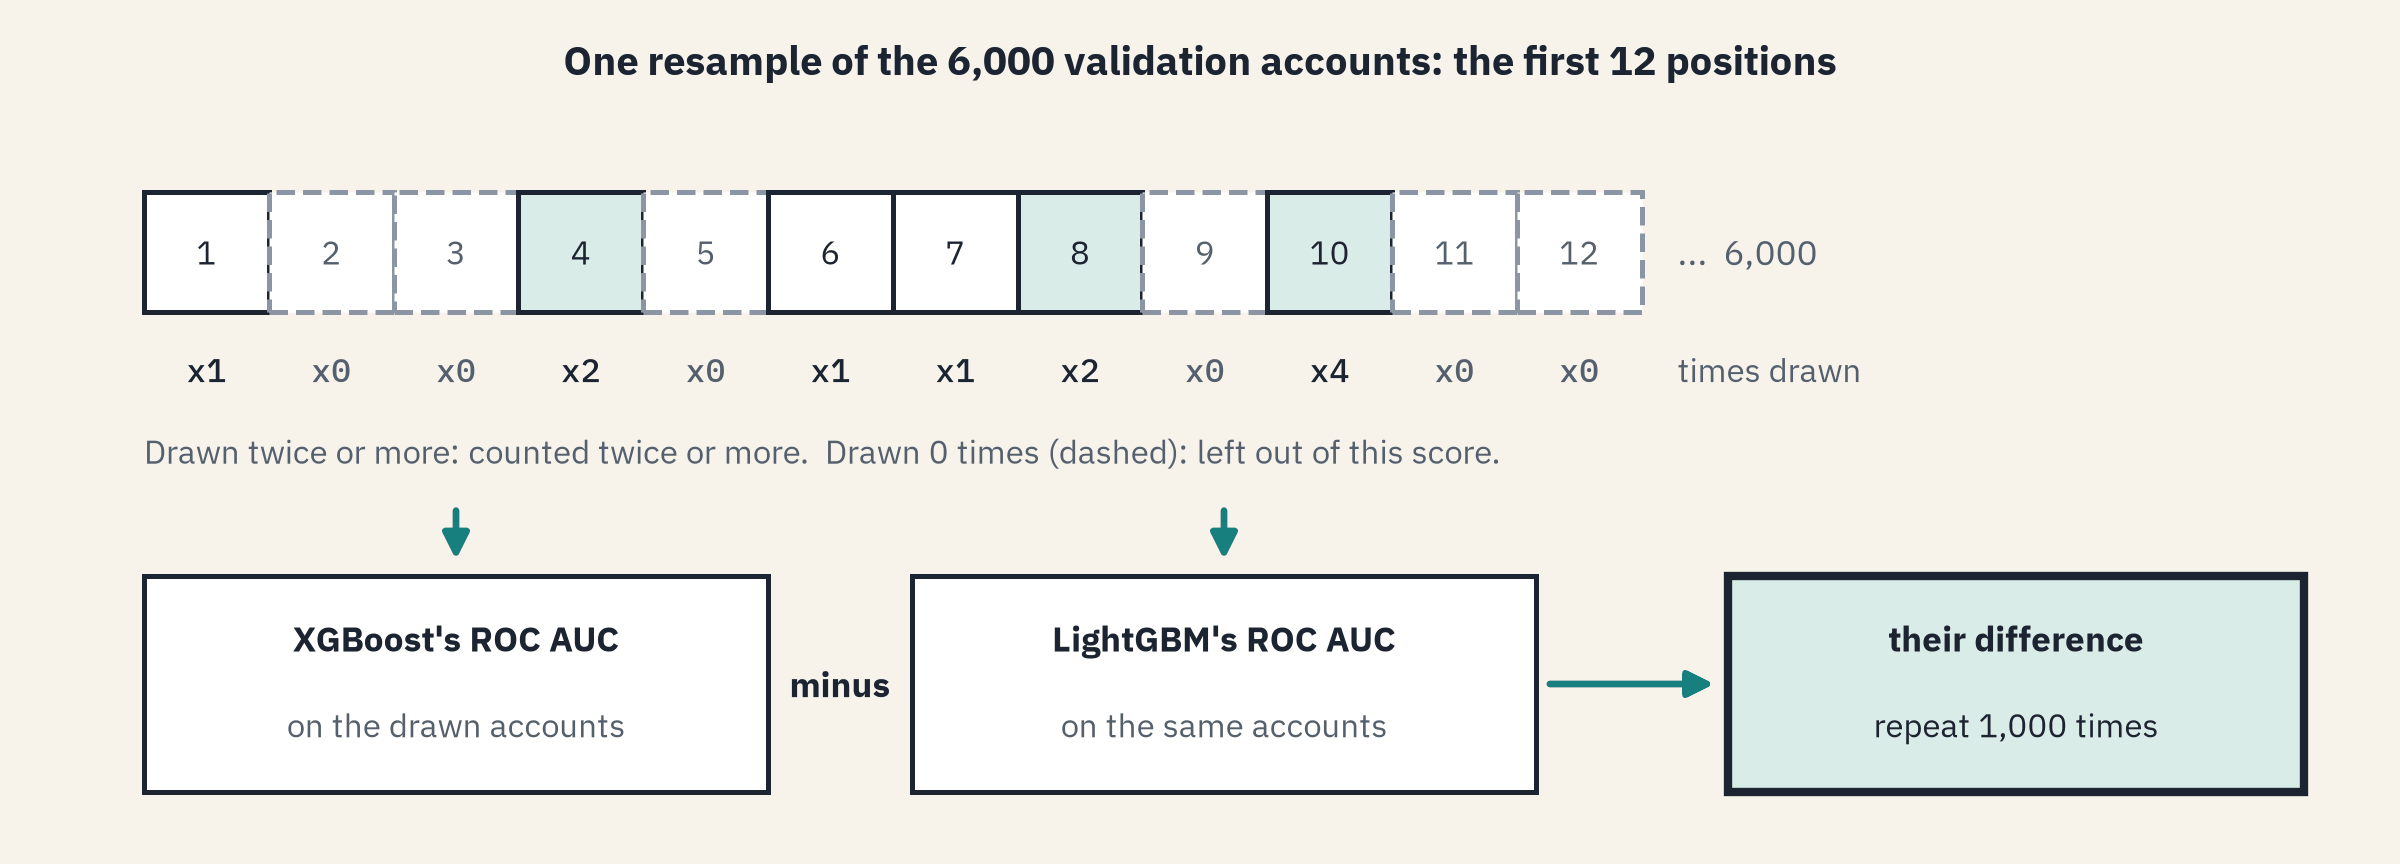)

## One Resample of the Validation Accounts

Day 1's bootstrap drew training rows with replacement and fitted a tree on each draw.
Here the draw runs on the 6,000 validation accounts and nothing is refitted: every model is scored on the same drawn accounts, 1,000 times.
The middle 95 percent of a model's 1,000 scores is a **95 percent bootstrap interval**: how far the score moves with which accounts happen to be scored.

In [14]:
# 1,000 resamples of 6,000 positions, drawn with replacement by a seeded generator: one row per resample
rng = np.random.default_rng(SEED)
draws = rng.choice(6000, size=(1000, 6000))
print("First resample, times positions 1 to 12 were drawn:", np.bincount(draws[0], minlength=6000)[:12])

# every model's ROC AUC on every resample: 1,000 rows, one column per model
y_values = y_valid.to_numpy()
aucs = pd.DataFrame([[roc_auc_score(y_values[d], outputs[name].to_numpy()[d]) for name in outputs] for d in draws],
                    columns=outputs.columns)
print(aucs.shape)

First resample, times positions 1 to 12 were drawn: [1 0 0 2 0 1 1 2 0 4 0 0]
(1000, 7)


## Each Model's Interval

`np.quantile(values, [0.025, 0.975])` gives two quantiles at once: the ends of the middle 95 percent.

In [15]:
# the 95 percent bootstrap interval of XGBoost's and of LightGBM's validation ROC AUC
for name in ["XGBoost", "LightGBM"]:
    low, high = np.quantile(aucs[name], [0.025, 0.975])
    print(name, " interval:", round(low, 4), "to", round(high, 4), " width:", round(high - low, 4))
print("XGBoost minus LightGBM on all 6,000 accounts:", round(scores.loc["XGBoost", "validation"] - scores.loc["LightGBM", "validation"], 4))

XGBoost  interval: 0.768 to 0.7962  width: 0.0282
LightGBM  interval: 0.7653 to 0.7939  width: 0.0286
XGBoost minus LightGBM on all 6,000 accounts: 0.0027


Each interval is close to three hundredths wide, ten times the 0.0027 between the two models, and the two overlap almost wholly.

**Predict 1**

Q. Each model's interval is about 0.028 wide. On the same 1,000 resamples, how wide will the interval of XGBoost's score minus LightGBM's be? Write down a number.

## The Paired Difference

A **paired difference** subtracts two models' scores on the same resample, so both are judged on the same accounts each time.

In [16]:
# XGBoost minus LightGBM on each resample, its interval, and how closely the two scores move together
difference = aucs["XGBoost"] - aucs["LightGBM"]
low, high = np.quantile(difference, [0.025, 0.975])
print("Difference interval:", round(low, 4), "to", round(high, 4), " width:", round(high - low, 4))
print("Correlation of the two scores across resamples:", round(aucs["XGBoost"].corr(aucs["LightGBM"]), 3))
print("Resamples where XGBoost scores higher:", (difference > 0).sum(), "of 1,000")

Difference interval: -0.0007 to 0.0064  width: 0.0071
Correlation of the two scores across resamples: 0.968
Resamples where XGBoost scores higher: 927 of 1,000


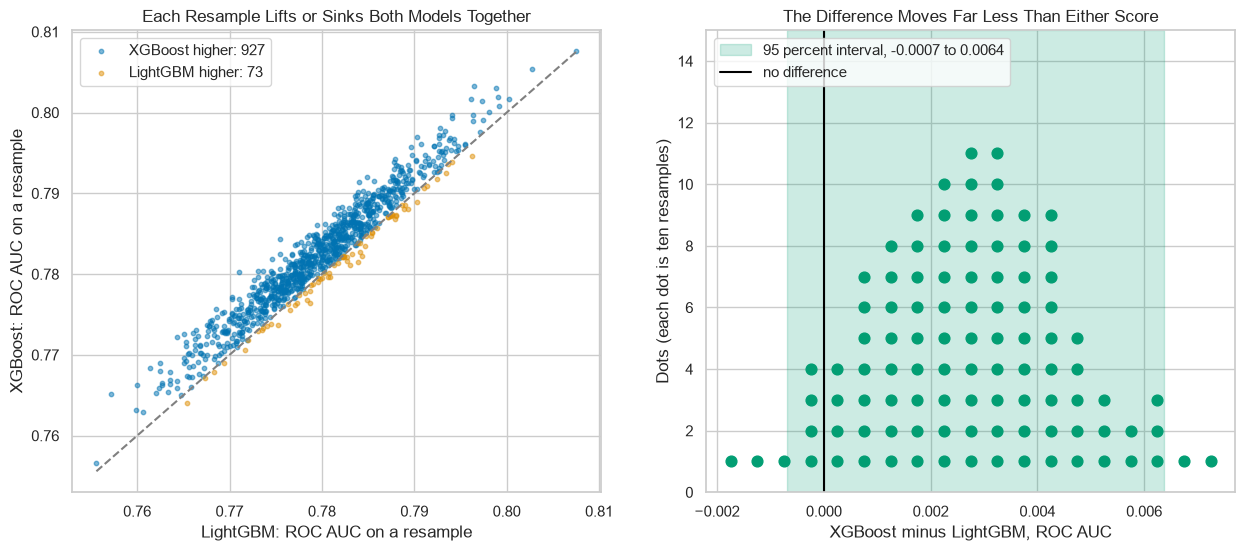

In [17]:
# left: each resample as a dot, one score against the other; right: the 1,000 differences as a dot histogram
def draw_pair(first, second, axes):
    gap = aucs[first] - aucs[second]
    low, high = np.quantile(gap, [0.025, 0.975])
    above = gap > 0
    axes[0].scatter(aucs[second][above], aucs[first][above], s=10, alpha=0.5, label=f"{first} higher: {above.sum()}")
    axes[0].scatter(aucs[second][~above], aucs[first][~above], s=10, alpha=0.5, label=f"{second} higher: {(~above).sum()}")
    edges = [aucs[[first, second]].min().min(), aucs[[first, second]].max().max()]
    axes[0].plot(edges, edges, color="gray", linestyle="--")
    axes[0].set(xlabel=f"{second}: ROC AUC on a resample", ylabel=f"{first}: ROC AUC on a resample",
                title="Each Resample Lifts or Sinks Both Models Together")
    axes[0].legend(loc="upper left")
    # one dot for every ten resamples: every tenth difference in order, rounded down (np.floor) to a bin 0.0005 wide
    bins = np.floor(np.sort(gap)[5::10] / 0.0005) * 0.0005 + 0.00025
    # cumcount() numbers the dots inside each bin 0, 1, 2, ..., so each dot sits on the one before
    heights = pd.Series(bins).groupby(bins).cumcount() + 1
    axes[1].axvspan(low, high, color="C2", alpha=0.2, label=f"95 percent interval, {low:.4f} to {high:.4f}")
    axes[1].scatter(bins, heights, s=60, color="C2")
    axes[1].axvline(0, color="black", linewidth=1.5, label="no difference")
    axes[1].set(ylim=(0, heights.max() + 4), xlabel=f"{first} minus {second}, ROC AUC",
                ylabel="Dots (each dot is ten resamples)", title="The Difference Moves Far Less Than Either Score")
    axes[1].legend(loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
draw_pair("XGBoost", "LightGBM", axes)
plt.show()

A **dot histogram** stacks one dot per group of resamples, so the count can be read dot by dot.

An easy resample is easy for both models: the cloud hugs the dashed line where the two scores are equal, so their difference barely moves.

The paired interval is about a quarter as wide as either model's own, and it still just reaches below zero: on these accounts XGBoost's lead is not wider than the noise.

The interval covers which accounts were scored, never a refit with another seed or other training rows.

### Your Turn: Pick Any Two Models

Pick two models and watch where the cloud sits against the dashed line, and where the band sits against zero.

In [18]:
# your turn: two dropdowns of model names redraw both panels
def compare(first="XGBoost", second="LightGBM"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    draw_pair(first, second, axes)
    plt.show()

interact(compare, first=list(aucs.columns), second=list(aucs.columns));

interactive(children=(Dropdown(description='first', index=4, options=('logistic', 'pruned tree', 'forest', 'Ad…

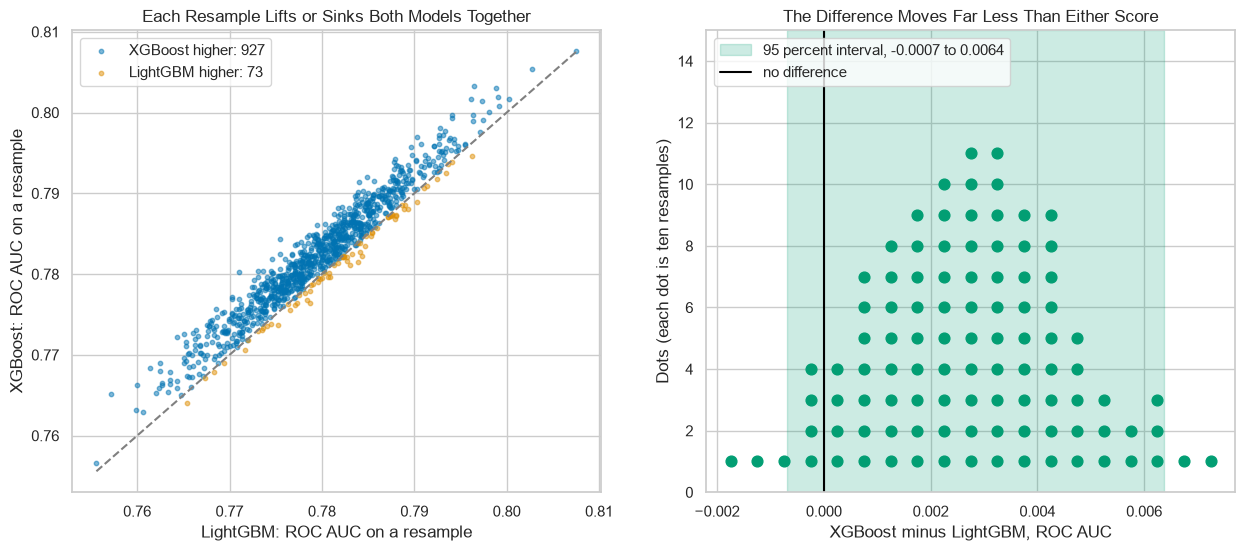

In [19]:
# the dropdowns' starting pair, drawn as a still picture (dropdowns do not run on GitHub)
compare("XGBoost", "LightGBM")

**Two models scored on the same accounts are compared by their paired difference, never by two separate intervals.**

# Model Performance Improvement

## A Small Grid for LightGBM

Day 9 measured LightGBM's settings one at a time on the folds; here two of them are searched together with Course 4's `GridSearchCV`, at 300 trees.

In [20]:
# three learning rates by three leaf counts, each scored by ROC AUC on today's five folds (45 fits)
grid = {"learning_rate": [0.02, 0.05, 0.1], "num_leaves": [8, 16, 32]}
search = GridSearchCV(LGBMClassifier(n_estimators=300, random_state=SEED, n_jobs=1, verbose=-1), grid, cv=folds,
                      scoring="roc_auc", n_jobs=1)
search.fit(X_train, y_train)
results = pd.DataFrame(search.cv_results_)
grid_scores = results.pivot(index="param_learning_rate", columns="param_num_leaves", values="mean_test_score")

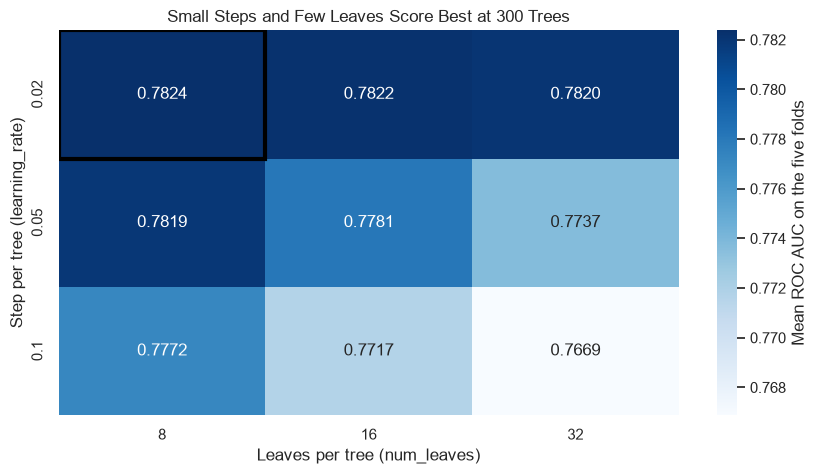

In [21]:
# the grid as an annotated heatmap, the best cell outlined
ax = sns.heatmap(grid_scores, annot=True, fmt=".4f", cmap="Blues", cbar_kws={"label": "Mean ROC AUC on the five folds"})
row = list(grid_scores.index).index(search.best_params_["learning_rate"])
column = list(grid_scores.columns).index(search.best_params_["num_leaves"])
ax.add_patch(plt.Rectangle((column, row), 1, 1, fill=False, edgecolor="black", linewidth=3))
ax.set(xlabel="Leaves per tree (num_leaves)", ylabel="Step per tree (learning_rate)")
ax.set_title("Small Steps and Few Leaves Score Best at 300 Trees")
plt.show()

In [22]:
# the best cell, its fold mean, and how far the folds spread around each cell's mean
print(search.best_params_, " best_score_:", round(search.best_score_, 4))
print("Fold standard deviations:", round(results["std_test_score"].min(), 4), "to", round(results["std_test_score"].max(), 4))

{'learning_rate': 0.02, 'num_leaves': 8}  best_score_: 0.7824
Fold standard deviations: 0.0013 to 0.0034


The top cells sit within a few ten-thousandths of each other, inside one fold standard deviation.

`GridSearchCV` refits the best cell on all 18,000 training rows: that refit is `search.best_estimator_`.

**Predict 2**

Q. The best cell scores 0.7824 on the folds that chose it, and Day 9's LightGBM scores 0.7799 on validation. Write down the tuned LightGBM's validation ROC AUC.

## The Tuned LightGBM on the Validation Rows

In [23]:
# the tuned model joins the others; its validation scores
models["tuned LightGBM"] = search.best_estimator_
outputs["tuned LightGBM"] = models["tuned LightGBM"].predict_proba(X_valid)[:, 1]
print("Validation ROC AUC:", round(roc_auc_score(y_valid, outputs["tuned LightGBM"]), 4),
      " Average precision:", round(average_precision_score(y_valid, outputs["tuned LightGBM"]), 4))

Validation ROC AUC: 0.7785  Average precision: 0.5473


The tuned model lands below the score that chose it, and below Day 9's untuned LightGBM.

`best_score_` is the best of nine noisy fold means, picked on the rows that scored it, so it leans high; Day 11 measures by how much.

**The grid's best cell looked better than Day 9's LightGBM only on the folds that chose it.**

# Final Model Selection

![The 30,000 card accounts drawn to scale: 18,000 training accounts in five folds of 3,600, where every model is fitted and every setting and threshold chosen; 6,000 validation accounts that only report; 6,000 test accounts never scored. Below, one of five fits: fitted on four folds, it gives the fifth fold its outputs. Put together, the five fits give 18,000 out-of-fold outputs, one per training account, made by cross_val_predict, and the threshold is read from them.](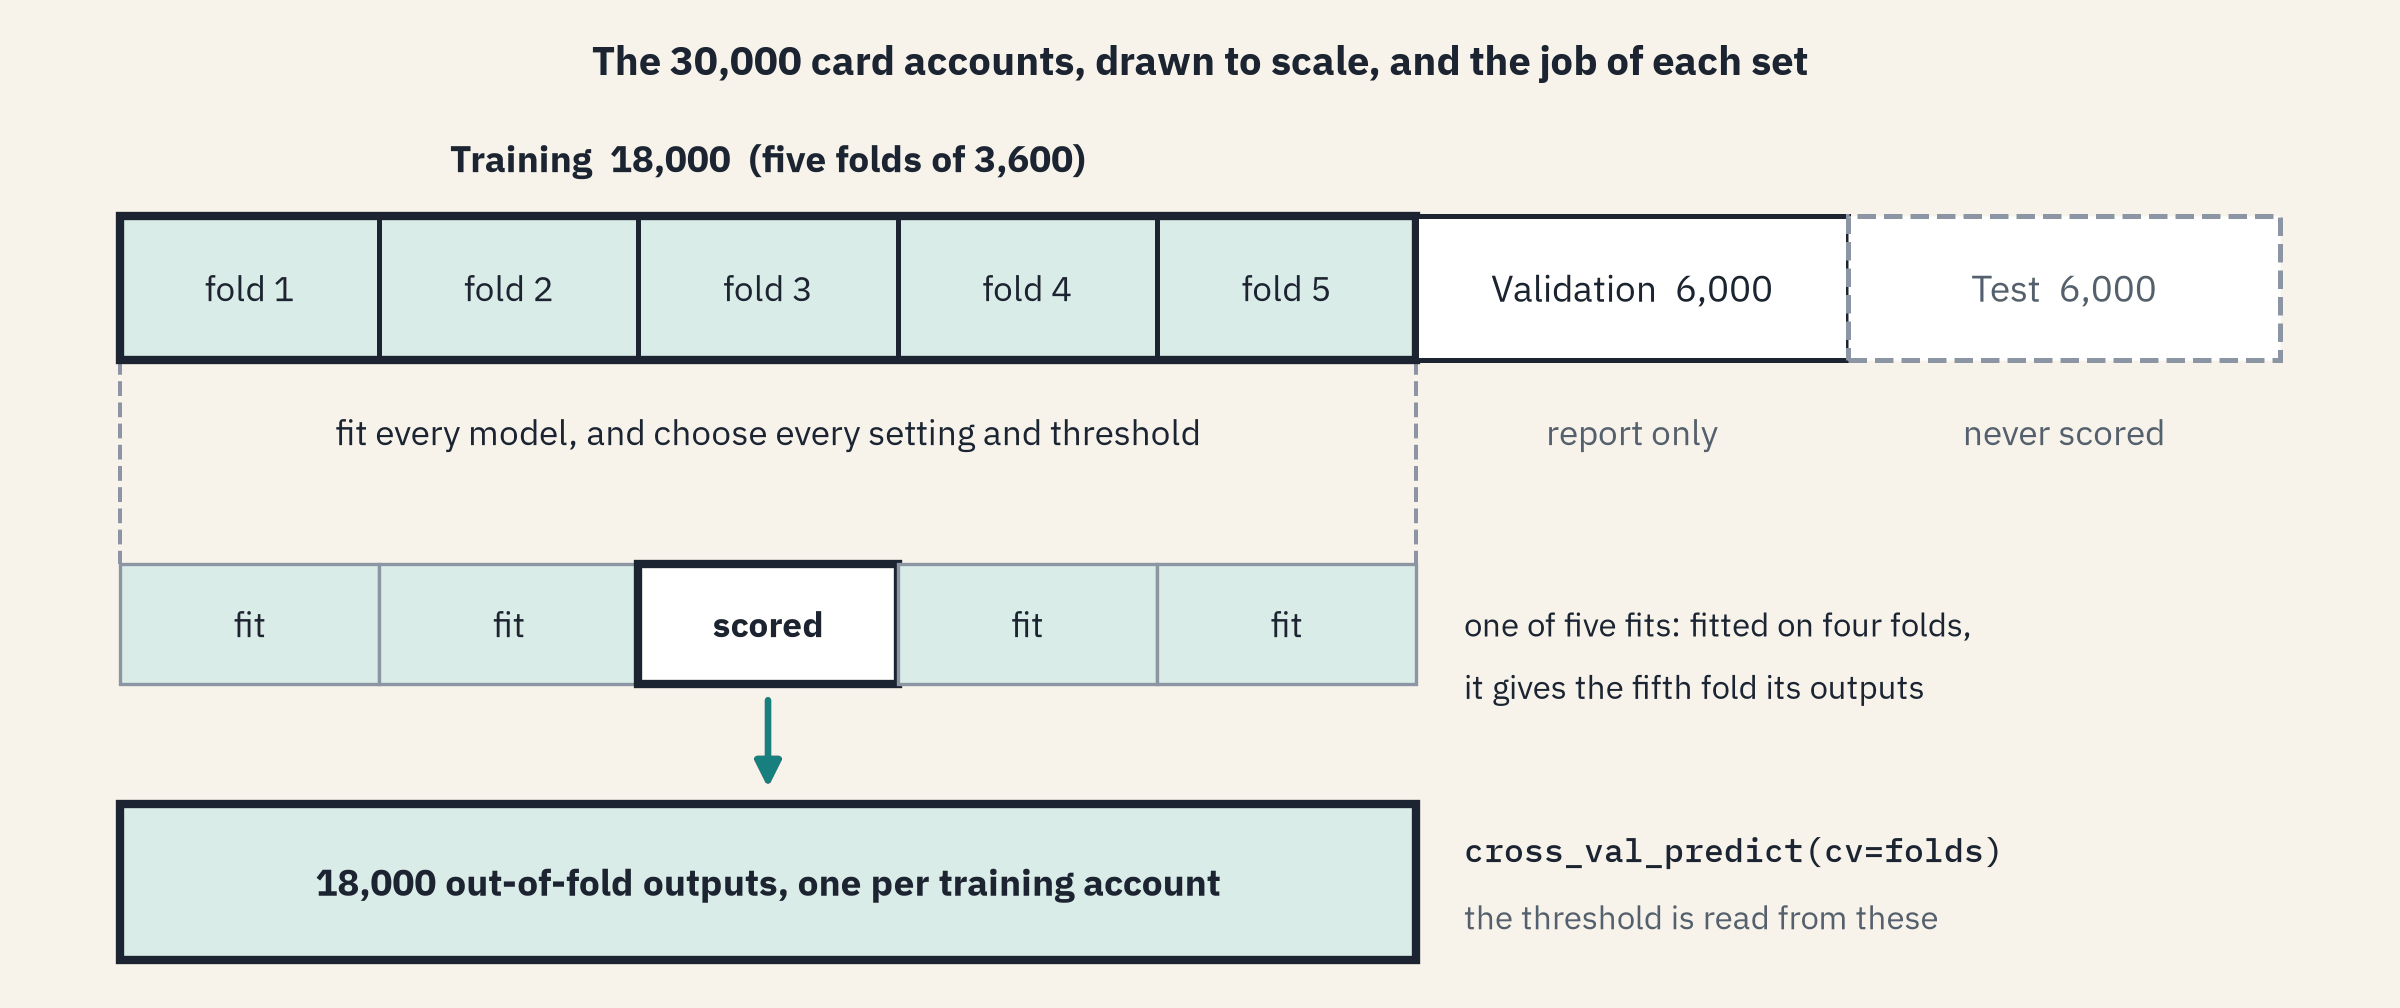)

## Out-of-Fold Outputs for Every Model

A threshold read from the validation rows would choose on the rows that report.
A threshold read from a model's outputs on the rows it was fitted on trusts a model that has partly memorised them.
Out-of-fold outputs avoid both: `cross_val_predict(..., method="predict_proba")` gives each training account the output of the fit that never saw it.
The stack's own column would refit every member inside every fold, so its layer alone is cross-validated on the members' columns, the inputs it was built on.

In [24]:
# out-of-fold outputs for the three models not yet folded
for name in ["pruned tree", "AdaBoost", "tuned LightGBM"]:
    oof[name] = cross_val_predict(models[name], X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]

# the stack: its layer cross-validated on the four members' columns
oof["stack"] = cross_val_predict(LogisticRegression(), oof[MEMBERS], y_train, cv=folds, method="predict_proba",
                                 n_jobs=1)[:, 1]
oof = oof[outputs.columns]
oof.shape

(18000, 8)

## Thresholds for a Recall of 0.70

Course 4's Day 8 rule, as a function of any outputs: the highest threshold whose recall is at least the target.

In [25]:
# every threshold's precision and recall on these outputs, then the highest threshold that reaches the target recall
def threshold_for_recall(target, output, target_recall=0.70):
    precision, recall, thresholds = precision_recall_curve(target, output)
    return thresholds[recall[:-1] >= target_recall].max()

# each model's pooled out-of-fold ROC AUC, its threshold, and the share of training accounts it flags there
selection = pd.DataFrame({"out-of-fold ROC AUC": [roc_auc_score(y_train, oof[name]) for name in oof],
                          "threshold": [threshold_for_recall(y_train, oof[name]) for name in oof]}, index=oof.columns)
selection["flagged share"] = [(oof[name] >= selection.loc[name, "threshold"]).mean() for name in oof]
selection.sort_values("out-of-fold ROC AUC", ascending=False)

,out-of-fold ROC AUC,threshold,flagged share
stack,0.7843,0.1625,0.3735
XGBoost,0.7839,0.1895,0.3724
forest,0.7832,0.1881,0.3728
LightGBM,0.7822,0.1849,0.3758
tuned LightGBM,0.7820,0.1844,0.3752
AdaBoost,0.7741,0.4009,0.3836
pruned tree,0.7603,0.4015,0.4231
logistic,0.7273,0.2047,0.4647


**Pooled out-of-fold ROC AUC** scores all 18,000 out-of-fold outputs at once, rather than averaging five fold scores.

The stack leads, with XGBoost and the forest within about a thousandth; the tuned LightGBM sits just under Day 9's LightGBM, as it did on validation.

AdaBoost's and the pruned tree's thresholds sit near 0.40: each output is the model's score, not a probability of default (Day 6, Course 4's Day 9).

**The stack goes forward with its out-of-fold threshold, chosen before one validation account is scored.**

# Model Performance Comparison

## Recall on Validation at the Out-of-Fold Thresholds

**Predict 3**

Q. Each threshold gave a recall of 0.70 on its model's out-of-fold outputs. How many of the eight models reach 0.70 on the validation rows? Write down a count.

In [26]:
# each model at its out-of-fold threshold: recall on the out-of-fold outputs, then recall and precision on validation
report = pd.DataFrame(index=oof.columns)
report["out-of-fold recall"] = [recall_score(y_train, oof[name] >= selection.loc[name, "threshold"]) for name in oof]
report["validation recall"] = [recall_score(y_valid, outputs[name] >= selection.loc[name, "threshold"]) for name in oof]
report["validation precision"] = [precision_score(y_valid, outputs[name] >= selection.loc[name, "threshold"]) for name in oof]
report

,out-of-fold recall,validation recall,validation precision
logistic,0.7002,0.6956,0.3319
pruned tree,0.7127,0.7174,0.3788
forest,0.7002,0.7008,0.4214
AdaBoost,0.7002,0.6888,0.4021
XGBoost,0.7002,0.6873,0.4159
LightGBM,0.7002,0.6888,0.4197
stack,0.7002,0.6910,0.4172
tuned LightGBM,0.7002,0.6910,0.4068


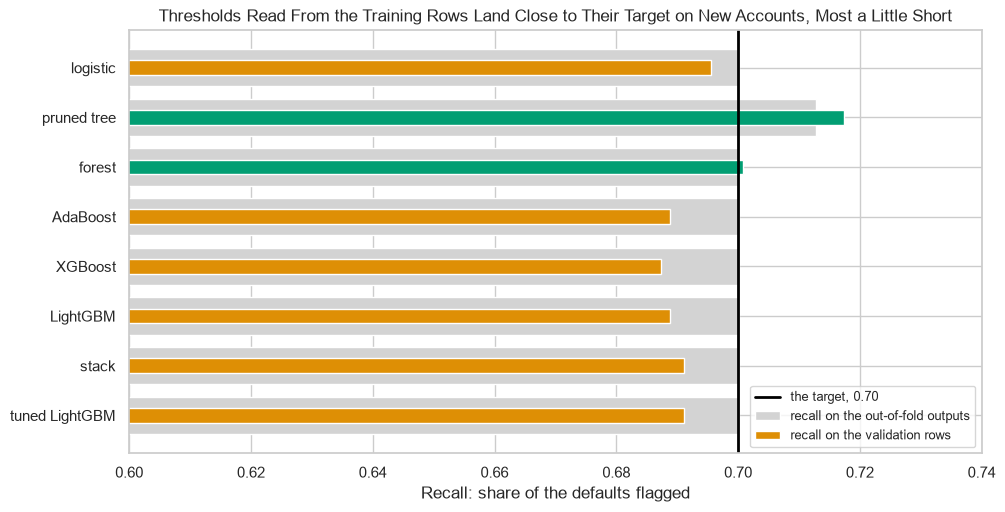

In [27]:
# a bullet chart: out-of-fold recall as a wide pale bar, validation recall as a narrow bar on it, the target as a line
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(report.index, report["out-of-fold recall"], height=0.75, color="lightgray", label="recall on the out-of-fold outputs")
ax.barh(report.index, report["validation recall"], height=0.3,
        color=["C2" if r >= 0.70 else "C1" for r in report["validation recall"]], label="recall on the validation rows")
ax.axvline(0.70, color="black", linewidth=2, label="the target, 0.70")
ax.set(xlim=(0.6, 0.74), xlabel="Recall: share of the defaults flagged")
ax.invert_yaxis()
ax.set_title("Thresholds Read From the Training Rows Land Close to Their Target on New Accounts, Most a Little Short")
ax.legend(loc="lower right", fontsize=9)
plt.show()

Only the pruned tree and the forest reach 0.70 on validation, the two green bars; the other six land between 0.6873 and 0.6956.

A threshold fitted to one set of defaults carries that set's noise to another, so the recall on new accounts lands near the target, not on it.

## Why Not the Fitted Outputs?

In [28]:
# the forest's threshold read from its outputs on its own fitted rows instead, and the recall each gives on validation
own_threshold = threshold_for_recall(y_train, fitted["forest"])
for label, threshold in [("fitted outputs", own_threshold), ("out-of-fold outputs", selection.loc["forest", "threshold"])]:
    print(label, " threshold:", round(threshold, 4), " validation recall:", round(recall_score(y_valid, outputs["forest"] >= threshold), 4))

fitted outputs  threshold: 0.2049  validation recall: 0.6737
out-of-fold outputs  threshold: 0.1881  validation recall: 0.7008


The forest's outputs on its own rows run higher than on unseen ones, so their threshold is set too high and falls well short of the target on new accounts.

## Every Score With Its Interval

In [29]:
# the tuned model scored on the same 1,000 resamples, then every model's score with its 95 percent interval
aucs["tuned LightGBM"] = [roc_auc_score(y_values[d], outputs["tuned LightGBM"].to_numpy()[d]) for d in draws]
board = pd.DataFrame({"ROC AUC": [roc_auc_score(y_valid, outputs[name]) for name in aucs],
                      "low": aucs.quantile(0.025), "high": aucs.quantile(0.975)}, index=aucs.columns).sort_values("ROC AUC")
board

,ROC AUC,low,high
logistic,0.7190,0.7010,0.7352
pruned tree,0.7627,0.7476,0.7784
AdaBoost,0.7708,0.7571,0.7853
tuned LightGBM,0.7785,0.7638,0.7925
LightGBM,0.7799,0.7653,0.7939
XGBoost,0.7827,0.7680,0.7962
forest,0.7844,0.7701,0.7976
stack,0.7846,0.7705,0.7981


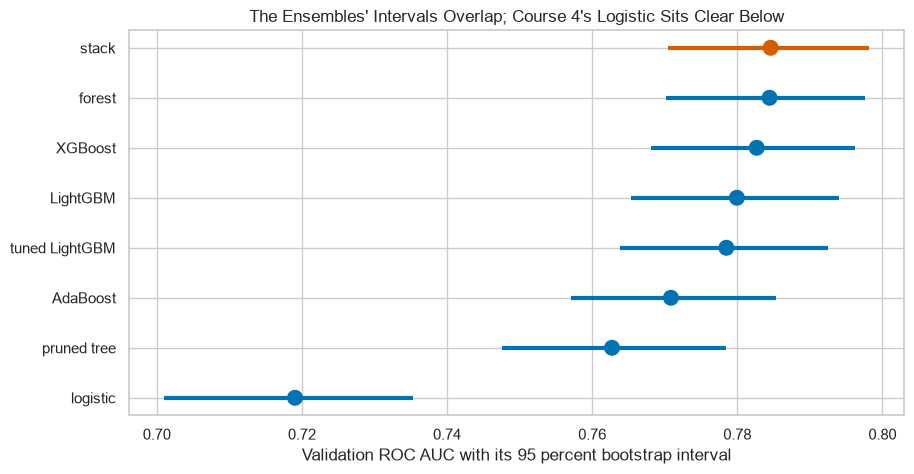

In [30]:
# a dot and whisker leaderboard, the chosen model in its own colour
colours = ["C3" if name == "stack" else "C0" for name in board.index]
plt.hlines(board.index, board["low"], board["high"], color=colours, linewidth=3)
plt.scatter(board["ROC AUC"], board.index, s=110, color=colours, zorder=3)
plt.xlabel("Validation ROC AUC with its 95 percent bootstrap interval")
plt.title("The Ensembles' Intervals Overlap; Course 4's Logistic Sits Clear Below")
plt.show()

## Who Tops the Board, Resample by Resample

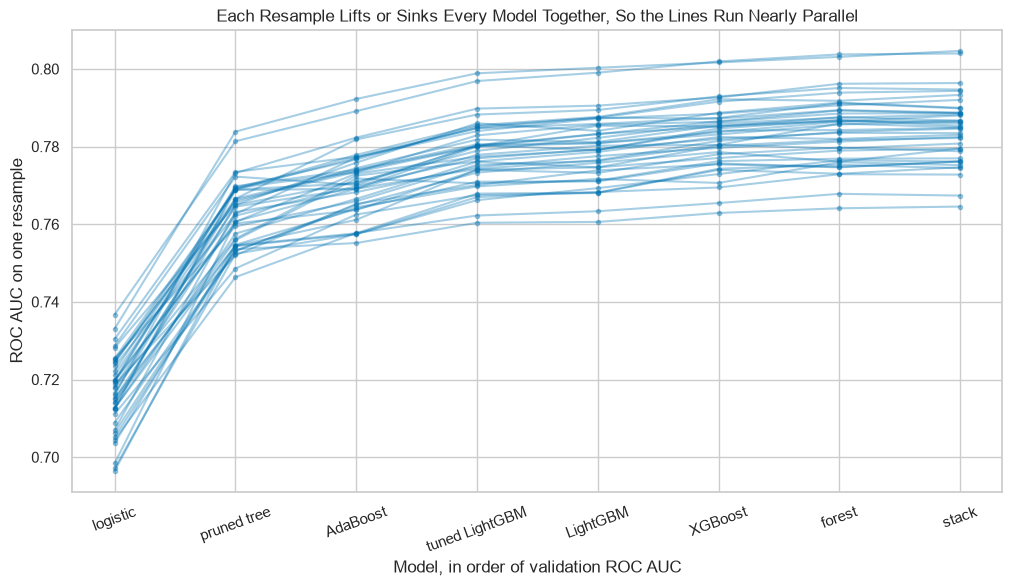

In [31]:
# 40 of the 1,000 resamples, each a line across the eight models in board order
order = list(board.index)
plt.figure(figsize=(12, 6))
for i in range(40):
    plt.plot(order, aucs.loc[i, order], color="C0", alpha=0.35, marker="o", markersize=3)
plt.xticks(rotation=20)
plt.xlabel("Model, in order of validation ROC AUC")
plt.ylabel("ROC AUC on one resample")
plt.title("Each Resample Lifts or Sinks Every Model Together, So the Lines Run Nearly Parallel")
plt.show()

`aucs.rank(axis=1, ascending=False)` ranks the models within each resample, 1 for the highest.

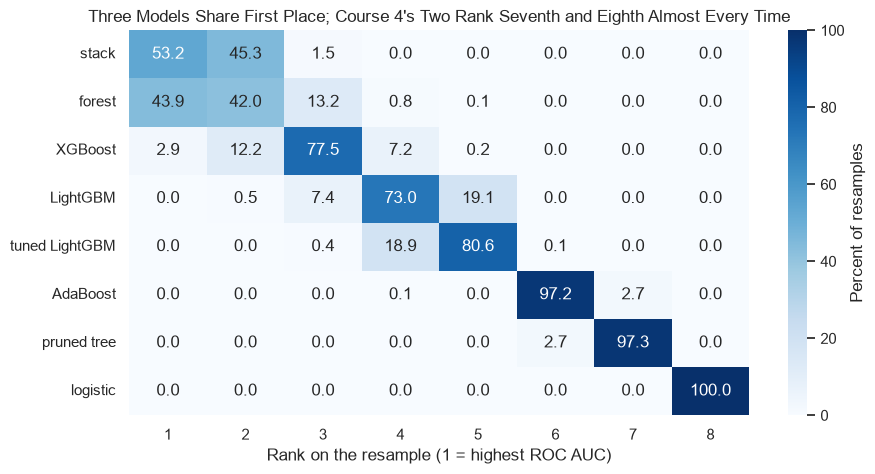

In [32]:
# each model's rank on each resample, then the percent of resamples at each rank, best model on top
ranks = aucs.rank(axis=1, ascending=False)
rank_shares = pd.DataFrame({rank: (ranks == rank).mean() * 100 for rank in range(1, 9)}).loc[order[::-1]]
ax = sns.heatmap(rank_shares, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Percent of resamples"})
ax.set(xlabel="Rank on the resample (1 = highest ROC AUC)", ylabel="")
ax.set_title("Three Models Share First Place; Course 4's Two Rank Seventh and Eighth Almost Every Time")
plt.show()

A resample that is hard for one model is hard for all of them, so the lines run nearly parallel and the order barely changes.

First place goes to the stack, the forest or XGBoost, and no other model takes it on any resample.

## The Chosen Model Against Each Other Model

**Predict 4**

Q. Against how many of the other seven models does the stack's paired interval lie wholly above zero? Write down a count.

In [33]:
# the stack minus each other model on every resample, and the 95 percent interval of each difference
others = [name for name in order if name != "stack"]
gaps = pd.DataFrame({name: np.quantile(aucs["stack"] - aucs[name], [0.025, 0.5, 0.975]) for name in others},
                    index=["low", "middle", "high"]).T
gaps["clear of zero"] = gaps["low"] > 0
gaps

,low,middle,high,clear of zero
logistic,0.0515,0.0651,0.0797,True
pruned tree,0.0145,0.0220,0.0294,True
AdaBoost,0.0079,0.0138,0.0191,True
tuned LightGBM,0.0029,0.0061,0.0097,True
LightGBM,0.0016,0.0046,0.0076,True
XGBoost,-0.0002,0.0019,0.0040,False
forest,-0.0021,0.0002,0.0023,False


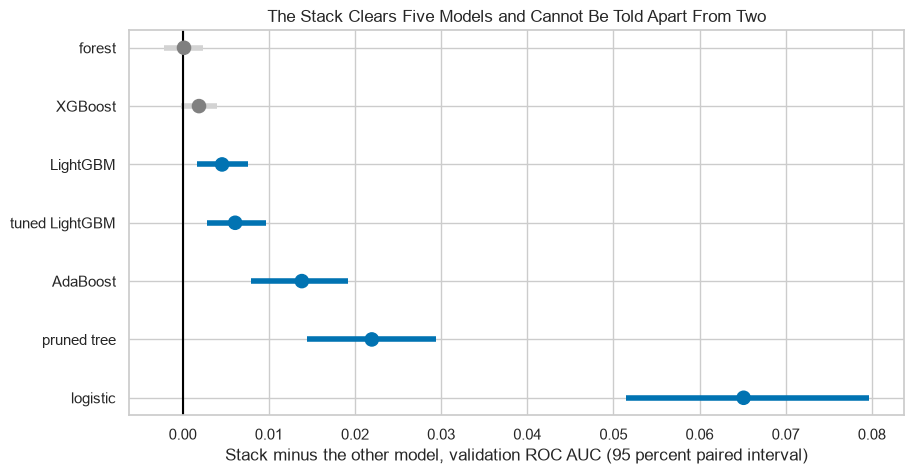

In [34]:
# each difference as a dot and whisker against zero, dark where the whole interval clears it
plt.hlines(gaps.index, gaps["low"], gaps["high"], color=np.where(gaps["clear of zero"], "C0", "lightgray"), linewidth=4)
plt.scatter(gaps["middle"], gaps.index, s=90, color=np.where(gaps["clear of zero"], "C0", "gray"), zorder=3)
plt.axvline(0, color="black")
plt.xlabel("Stack minus the other model, validation ROC AUC (95 percent paired interval)")
plt.title("The Stack Clears Five Models and Cannot Be Told Apart From Two")
plt.show()

Separate intervals overlap for every ensemble; paired, the stack clears LightGBM, the tuned LightGBM and AdaBoost as well as Course 4's two.

Against the forest and XGBoost the interval sits across zero.

**On validation the stack, the forest and XGBoost cannot be told apart; the stack was chosen inside the training rows, and the validation rows only report.**

# Reading the Chosen Model

## What the Stack Leans On

The stack has four models inside, so Day 4's permutation importance is written out as a loop: shuffle one column of the validation rows, score the stack again, and record the fall in ROC AUC, three times a column.

In [35]:
# each column shuffled three times on the validation rows: the fall in the stack's ROC AUC each time
stack_auc = roc_auc_score(y_valid, outputs["stack"])
falls = {}
for column in FEATURES:
    shuffled = X_valid.copy()
    drops = []
    for repeat in range(3):
        shuffled[column] = rng.permutation(X_valid[column].to_numpy())
        drops.append(stack_auc - roc_auc_score(y_valid, stack_output(shuffled)))
    falls[column] = drops
importance = pd.DataFrame(falls).T.agg(["mean", "std"], axis=1).sort_values("mean")

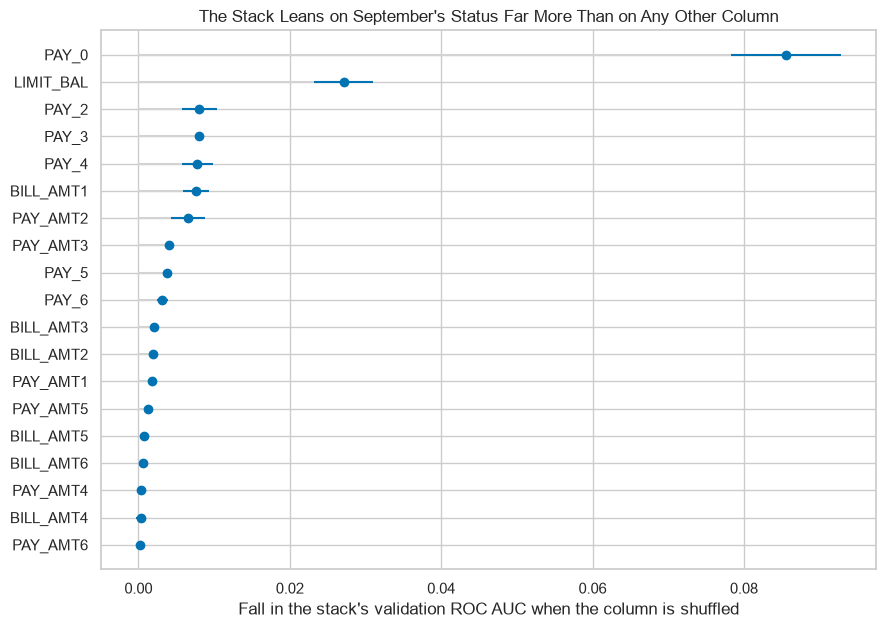

In [36]:
# a lollipop of the mean fall, one standard deviation either side as a whisker
plt.figure(figsize=(10, 7))
plt.hlines(importance.index, 0, importance["mean"], color="lightgray")
plt.errorbar(importance["mean"], importance.index, xerr=importance["std"], fmt="o", color="C0")
plt.xlabel("Fall in the stack's validation ROC AUC when the column is shuffled")
plt.title("The Stack Leans on September's Status Far More Than on Any Other Column")
plt.show()

In [37]:
# the three columns the stack leans on most
importance.sort_values("mean", ascending=False).head(3)

,mean,std
PAY_0,0.0856,0.0072
LIMIT_BAL,0.0271,0.0039
PAY_2,0.0081,0.0023


The stack leans on `PAY_0` most by far, then on the limit and August's status: an association in this file, and nothing more.

Course 4's Day 10 found that the four person columns added almost nothing to a cross-validated ROC AUC; they stay out of every model here, because a model using them would sort people by them.

## Are the Outputs Frequencies?

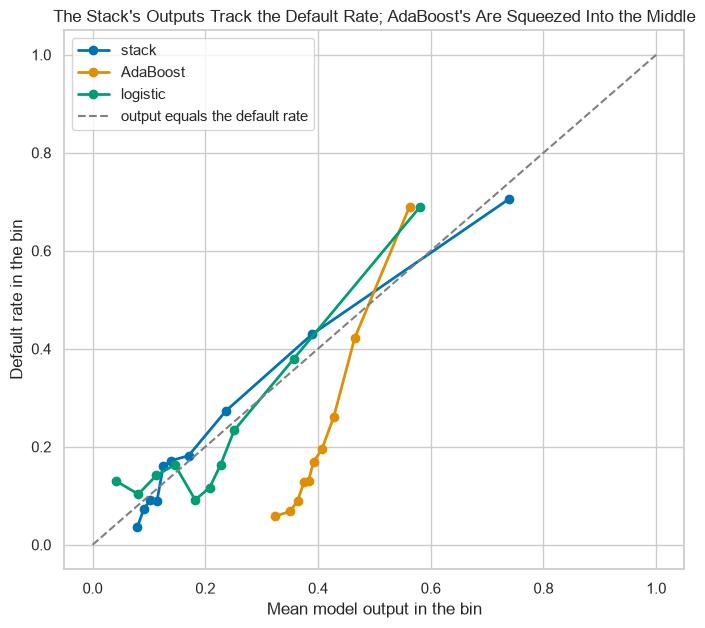

In [38]:
# Course 4's reliability diagram: ten bins of equal size, each bin's mean output against its default rate
plt.figure(figsize=(8, 7))
for name in ["stack", "AdaBoost", "logistic"]:
    rate, mean_output = calibration_curve(y_valid, outputs[name], n_bins=10, strategy="quantile")
    plt.plot(mean_output, rate, marker="o", linewidth=2, label=name)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="output equals the default rate")
plt.xlabel("Mean model output in the bin")
plt.ylabel("Default rate in the bin")
plt.title("The Stack's Outputs Track the Default Rate; AdaBoost's Are Squeezed Into the Middle")
plt.legend(loc="upper left")
plt.show()

The stack's bins sit near the dashed line, so its output reads as a probability of default on this file.

AdaBoost's outputs stay in a narrow band around the middle: the model's score ranks well and is not a frequency; Day 13 turns a score into a probability.

## Where It Fails

In [39]:
# the stack's flags at its out-of-fold threshold, and what happened to each validation account
flags = outputs["stack"] >= selection.loc["stack", "threshold"]
status_valid = X_valid["PAY_0"].clip(upper=3).to_numpy()
outcomes = pd.DataFrame({"TP": flags & (y_values == 1), "FN": ~flags & (y_values == 1), "FP": flags & (y_values == 0)})
print("Flagged:", flags.sum(), " Defaults caught:", outcomes["TP"].sum(), "of", y_values.sum(), " Missed:", outcomes["FN"].sum())
print("Misses at status 0 or below:", outcomes["FN"][status_valid <= 0].sum(),
      " Paid accounts flagged with a delay of a month or more:", outcomes["FP"][status_valid >= 1].sum(), "of", outcomes["FP"].sum())

Flagged: 2198  Defaults caught: 917 of 1327  Missed: 410
Misses at status 0 or below: 403  Paid accounts flagged with a delay of a month or more: 600 of 1281


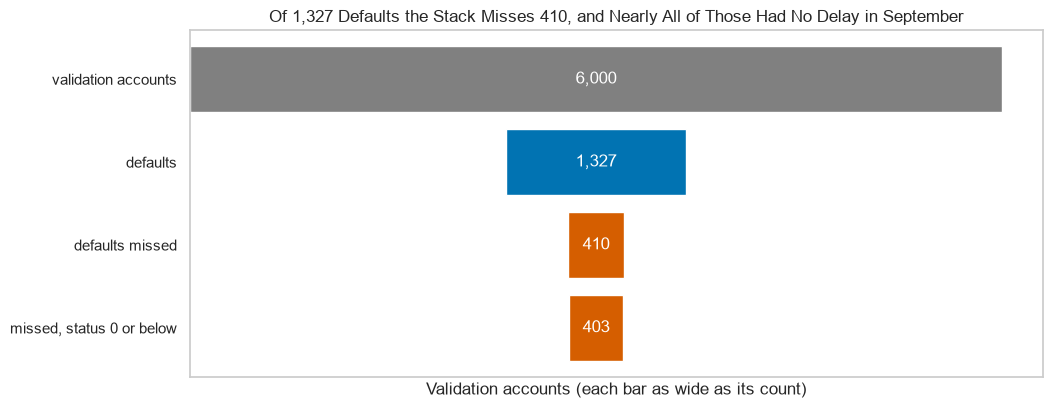

In [40]:
# a funnel: all validation accounts, the defaults among them, the defaults missed, and those with no delay in September
stages = {"validation accounts": len(y_values), "defaults": y_values.sum(), "defaults missed": outcomes["FN"].sum(),
          "missed, status 0 or below": outcomes["FN"][status_valid <= 0].sum()}
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(list(stages), list(stages.values()), left=[-v / 2 for v in stages.values()],
               color=["gray", "C0", CELL_COLOURS["FN"], CELL_COLOURS["FN"]])
ax.bar_label(bars, labels=[f"{v:,}" for v in stages.values()], label_type="center", color="white", fontsize=12)
ax.invert_yaxis()
ax.set_xticks([])
ax.grid(False)
ax.set_xlabel("Validation accounts (each bar as wide as its count)")
ax.set_title("Of 1,327 Defaults the Stack Misses 410, and Nearly All of Those Had No Delay in September")
plt.show()

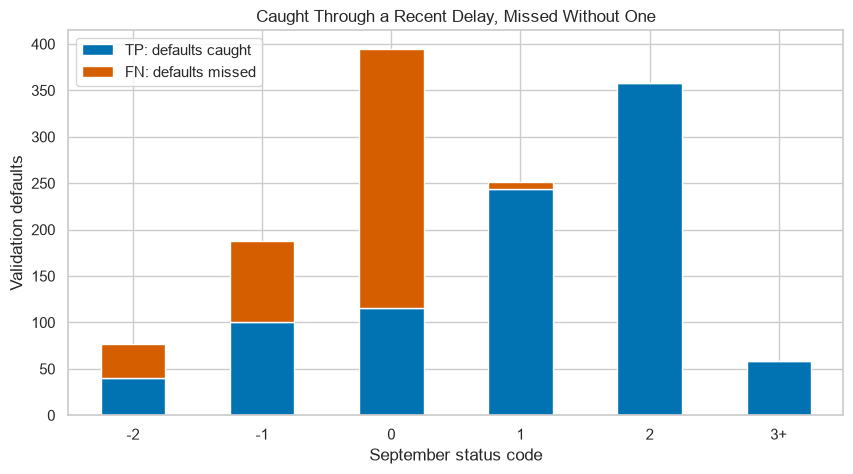

In [41]:
# defaults caught and missed by September status, stacked
by_code = outcomes[["TP", "FN"]].groupby(status_valid).sum()
by_code.index = ["-2", "-1", "0", "1", "2", "3+"]
by_code.plot.bar(stacked=True, color=[CELL_COLOURS["TP"], CELL_COLOURS["FN"]], figsize=(10, 5), rot=0)
plt.xlabel("September status code")
plt.ylabel("Validation defaults")
plt.legend(["TP: defaults caught", "FN: defaults missed"])
plt.title("Caught Through a Recent Delay, Missed Without One")
plt.show()

A **funnel chart** narrows from all the accounts to the ones that matter at each step, each bar as wide as its count.

At status 0 and below, taken together, the stack misses more defaults than it catches; from status 1 up it misses 7.

About half of its false flags carry a delay: the delay that finds the defaults also flags accounts that paid.

## Do the Best Three Miss the Same Defaults?

In [42]:
# the validation defaults each of the best three misses at its own out-of-fold threshold
missed = {name: (outputs[name] < selection.loc[name, "threshold"]).to_numpy() & (y_values == 1)
          for name in ["stack", "forest", "XGBoost"]}
s, f, x = missed["stack"], missed["forest"], missed["XGBoost"]
print({name: int(m.sum()) for name, m in missed.items()}, " Missed by all three:", (s & f & x).sum())

{'stack': 410, 'forest': 397, 'XGBoost': 415}  Missed by all three: 374


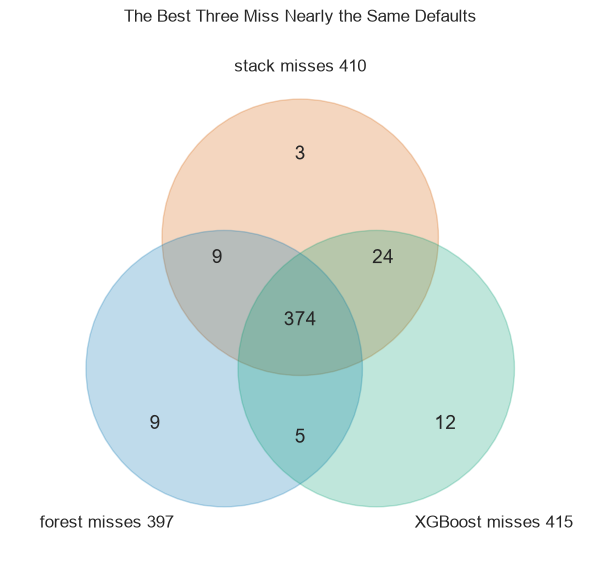

In [43]:
# a Venn diagram by hand: plt.Circle draws a circle, and each count sits where only its circles overlap
fig, ax = plt.subplots(figsize=(8, 7))
for centre, name, colour, label_at in [((0, 0.6), "stack", "C3", (0, 1.8)), ((-0.55, -0.35), "forest", "C0", (-1.4, -1.5)),
                                       ((0.55, -0.35), "XGBoost", "C2", (1.4, -1.5))]:
    ax.add_patch(plt.Circle(centre, 1, color=colour, alpha=0.25))
    ax.text(*label_at, f"{name} misses {missed[name].sum()}", ha="center", fontsize=12)
regions = {(0, 0): s & f & x, (0, 1.2): s & ~f & ~x, (-1.05, -0.75): ~s & f & ~x, (1.05, -0.75): ~s & ~f & x,
           (-0.6, 0.45): s & f & ~x, (0.6, 0.45): s & ~f & x, (0, -0.85): ~s & f & x}
for place, region in regions.items():
    ax.text(*place, f"{region.sum()}", ha="center", va="center", fontsize=14)
ax.set(xlim=(-2.1, 2.1), ylim=(-1.8, 2.1), aspect="equal", title="The Best Three Miss Nearly the Same Defaults")
ax.set_axis_off()
plt.show()

A **Venn diagram** draws each set as a circle, so an account missed by two models sits where their circles overlap.

374 defaults are missed by all three models; each misses only a handful the other two catch.

Choosing among the three changes little about which defaults go unflagged.

**The stack finds defaults through a recent delay and misses the ones that arrive without one, and so do the forest and XGBoost.**

# Insights and Conclusion

**What it separates:** the stack ranks unseen accounts at a validation ROC AUC of 0.7846 against 0.7190 for Course 4's logistic regression, by more than the noise.

**What the rows cannot separate:** the stack, the forest and XGBoost; each of the three ranks first on some resamples of these accounts.

**Where it is wrong:** defaults with no delay in September, nearly all of its misses, and the forest and XGBoost miss the same ones.

**What was not tested:** another period, a refit with another seed, any cost of an error, and the test rows.

**The stack clears Course 4's two models, AdaBoost and both LightGBMs by more than the noise; among the best three, the accounts cannot pick a winner.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit and compare many models on the same training and validation rows.
* Put a bootstrap interval on a validation score, and a paired interval on the gap between two models.
* Tune a booster with `GridSearchCV` inside the training rows and set its `best_score_` beside the validation score.
* Choose a model and a threshold from out-of-fold outputs and check them on rows that only report.
* Rank models resample by resample, and say what a model leans on and where it fails.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [44]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Recall Target of 0.60**

Q. Read each model's threshold for a recall of 0.60 from its out-of-fold outputs with `threshold_for_recall`. Store the precision of its flags on the validation rows in a dictionary `ex1_precision`, model name to precision rounded to 4 decimals.

In [45]:
# each model's out-of-fold threshold for 0.60, then the precision of its flags on the validation rows
ex1_precision = {}
for name in oof:
    threshold = threshold_for_recall(y_train, oof[name], 0.60)
    ex1_precision[name] = round(precision_score(y_valid, outputs[name] >= threshold), 4)
print(ex1_precision)

{'logistic': 0.4403, 'pruned tree': 0.4805, 'forest': 0.5026, 'AdaBoost': 0.4764, 'XGBoost': 0.501, 'LightGBM': 0.4941, 'stack': 0.5016, 'tuned LightGBM': 0.4895}


In [46]:
check("Exercise 1 precision at recall 0.60", ex1_precision, {"logistic": 0.4403, "pruned tree": 0.4805, "forest": 0.5026, "AdaBoost": 0.4764, "XGBoost": 0.501, "LightGBM": 0.4941, "stack": 0.5016, "tuned LightGBM": 0.4895})

Exercise 1 precision at recall 0.60: correct


At a recall of 0.60 the forest's flags are right most often on validation, 0.5026, with the stack at 0.5016 and XGBoost at 0.501.

A lower recall target buys precision for every model: fewer flags, and a larger share of them defaults.

### Exercise 2

**An Interval on Average Precision**

Q. On the same 1,000 resamples in `draws`, score the stack's validation outputs by average precision. Store the ends of its 95 percent bootstrap interval in `ex2_low` and `ex2_high`.

In [47]:
# the stack's average precision on each resample, then the middle 95 percent
stack_ap = np.array([average_precision_score(y_values[d], outputs["stack"].to_numpy()[d]) for d in draws])
ex2_low, ex2_high = np.quantile(stack_ap, [0.025, 0.975])
print(round(ex2_low, 4), round(ex2_high, 4), " width:", round(ex2_high - ex2_low, 4))

0.5288 0.5874  width: 0.0586


In [48]:
check("Exercise 2 the interval's low end", ex2_low, 0.5288193493676637)
check("Exercise 2 the interval's high end", ex2_high, 0.5874022960718914)

Exercise 2 the interval's low end: correct
Exercise 2 the interval's high end: correct


The stack's average precision moves from 0.5288 to 0.5874 with the accounts scored, an interval 0.0586 wide.

Average precision reads the top of the ranking, where fewer accounts sit, so it moves more from resample to resample than ROC AUC.

### Exercise 3

**A Paired Gap in Average Precision**

Q. On the same resamples, take the stack's average precision minus XGBoost's. Store the ends of the 95 percent interval of the difference in `ex3_low` and `ex3_high`, and whether the whole interval lies above zero in `ex3_clear` (`True` or `False`).

In [49]:
# XGBoost's average precision on the same resamples, the paired difference, and its interval
xgboost_ap = np.array([average_precision_score(y_values[d], outputs["XGBoost"].to_numpy()[d]) for d in draws])
ex3_low, ex3_high = np.quantile(stack_ap - xgboost_ap, [0.025, 0.975])
ex3_clear = bool(ex3_low > 0)
print(round(ex3_low, 4), round(ex3_high, 4), ex3_clear)

-0.0033 0.0074 False


In [50]:
check("Exercise 3 the interval's low end", ex3_low, -0.0033359082576976977)
check("Exercise 3 the interval's high end", ex3_high, 0.007351642123802557)
check("Exercise 3 clear of zero", ex3_clear, False)

Exercise 3 the interval's low end: correct
Exercise 3 the interval's high end: correct
Exercise 3 clear of zero: correct


The paired interval runs from -0.0033 to 0.0074 and covers zero: on average precision too, the stack and XGBoost cannot be told apart on these accounts.

### Exercise 4: AI check

**A Final Check on Fresh Rows**

You asked an AI assistant for one last check of the stack on rows nobody chose with.
This came back.
It runs, and the score looks better than any validation score today.
Test it, then find the one bug.

In [51]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def final_check():
    # a last check on fresh rows: split the accounts again and score the stack on the new test rows
    X_fit, X_fresh, y_fit, y_fresh = train_test_split(X, y, test_size=0.2, random_state=2026)
    return X_fresh, roc_auc_score(y_fresh, stack_output(X_fresh))

fresh_rows, fresh_auc = final_check()
print("ROC AUC on the fresh rows:", round(fresh_auc, 4))

ROC AUC on the fresh rows: 0.7955


In [52]:
# the test: no scored row may be one of the 6,000 test rows Course 5 keeps closed
opened = fresh_rows.index.intersection(X_test.index)
assert len(opened) == 0, f"{len(opened):,} of the scored rows are closed test rows"

AssertionError: 1,195 of the scored rows are closed test rows

Q. Fix the function so it scores the rows this notebook reports on.
Store the fixed function's ROC AUC in `ex4_auc`, and the number of training rows among the rows it scores in `ex4_seen`.

In [53]:
# what the fresh split scored: closed test rows, and training rows the stack was fitted on
print("Test rows:", len(opened), " Training rows:", len(fresh_rows.index.intersection(X_train.index)), "of", len(fresh_rows))

# the fix: a new split cannot make fresh rows, so score the validation rows, the rows that report
def final_check():
    return X_valid, roc_auc_score(y_valid, stack_output(X_valid))

fresh_rows, ex4_auc = final_check()
ex4_seen = len(fresh_rows.index.intersection(X_train.index))
print(round(ex4_auc, 4), ex4_seen)

Test rows: 1195  Training rows: 3621 of 6000
0.7846 0


In [54]:
check("Exercise 4 the ROC AUC", ex4_auc, 0.7845927743772002)
check("Exercise 4 training rows scored", ex4_seen, 0)

Exercise 4 the ROC AUC: correct
Exercise 4 training rows scored: correct


The new split scored 1,195 closed test rows and 3,621 rows the stack was fitted on, which is how it reached 0.7955, above every validation score.

A new `train_test_split` cannot make fresh rows: every account in the file already has a role, and only the validation rows report.

Fixed, the check returns the stack's validation ROC AUC, 0.7846, and scores no training row.

## Congratulations!

You ran the course's eight models on one set of accounts and refused to call a winner on a point score.
You put an interval on every score, then a paired interval on every gap, and saw how much tighter a fair comparison is.
You tuned a booster inside the training rows, read every threshold from out-of-fold outputs, and watched them land on new accounts.
You found where the chosen stack fails: defaults that arrive without a delay.
In Day 11 you measure how far a search's own best score leans, with randomized search and nested folds.

[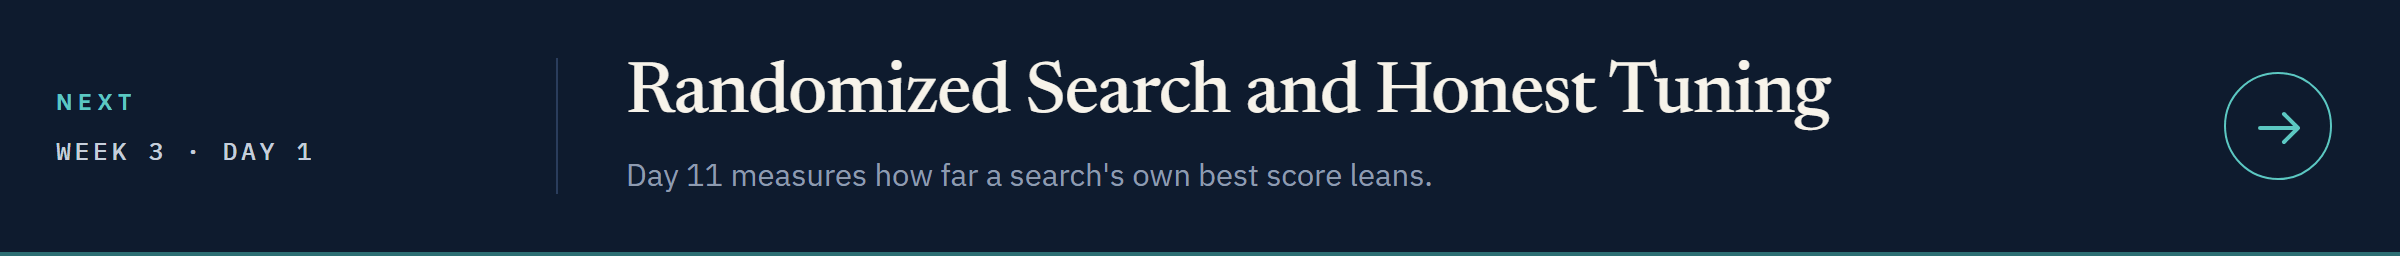](../../week3/day1/11_randomized_search_and_honest_tuning.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day1/11_randomized_search_and_honest_tuning.ipynb)